# Preprocessing C - Fused Magnitude and Signed I/Q for V6

This notebook defines the representation evaluated only by V6. V2 and V5 achieved nearly identical global Hungarian F1, but their occupancy-level results were complementary: magnitude was stronger for one-person scenes, while signed I/Q substantially improved two-person F1. V6 therefore concatenates both representations without changing the fixed split, target policy, model architecture, loss, or evaluator.

## 1. Setup, authentication, and fixed split

In [1]:
%matplotlib inline

import getpass
import importlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import preprocessing as preprocessing_module
preprocessing_module = importlib.reload(preprocessing_module)
from preprocessing import (
    PreprocessingConfig, normalize_per_radar_channel,
    per_radar_channel_moments, transform_fused_magnitude_iq,
)

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])

ARTIFACT_DIR = SRC_DIR / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
with (ARTIFACT_DIR / 'data_split.json').open(encoding='utf-8') as handle:
    split = json.load(handle)
TRAIN_WINDOWS = split['train_windows']
VALIDATION_WINDOWS = split['validation_windows']
assert set(TRAIN_WINDOWS).isdisjoint(VALIDATION_WINDOWS)
print('Training windows:', TRAIN_WINDOWS)
print('Validation windows:', VALIDATION_WINDOWS)

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti
Training windows: [0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 19, 20, 21, 22]
Validation windows: [3, 9, 14, 18, 23]


## 2. Resolve cached dataset windows

The same Hugging Face files and split used by all previous experiments are reused. No validation observation contributes to preprocessing statistics.

In [2]:
REPO_ID = 'HAEEAI/multi-person-localization'
window_paths = {}
for index in sorted(TRAIN_WINDOWS + VALIDATION_WINDOWS):
    filename = f'data/window_{index:06d}.npz'
    window_paths[index] = Path(hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    ))
print(f'{len(window_paths)} cached windows are ready.')

24 cached windows are ready.


## 3. Define the fused representation

For each radar, the first three channels contain log-compressed antenna magnitudes and the next six contain signed-log I/Q pairs. The resulting shape is `(T, 6, 9, 120)`. This deterministic transform adds no state and is suitable for the final inference code.

In [3]:
V6_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5),
    antenna_mode='none', range_bin_start=0, range_bin_stop=120,
    log_compression=True, background_mode='none',
)
V6_CHANNEL_ORDER = [
    'A0-mag', 'A1-mag', 'A2-mag',
    'A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q',
]
with np.load(window_paths[TRAIN_WINDOWS[0]], allow_pickle=False) as data:
    fused_sample = transform_fused_magnitude_iq(data['radar_cir_iq'][:256], V6_CONFIG)
print('Fused sample shape:', fused_sample.shape)
print('Finite values:', bool(np.isfinite(fused_sample).all()))
assert fused_sample.shape == (256, 6, 9, 120)

Fused sample shape: (256, 6, 9, 120)
Finite values: True


## 4. Estimate leakage-free training statistics

In [4]:
CHUNK_SIZE = 256

def training_feature_blocks():
    for window_index in TRAIN_WINDOWS:
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            for start in range(0, len(radar), CHUNK_SIZE):
                yield transform_fused_magnitude_iq(
                    radar[start:start + CHUNK_SIZE], V6_CONFIG
                )

V6_MEAN, V6_STD, V6_VALUES_PER_CHANNEL = per_radar_channel_moments(
    training_feature_blocks()
)
assert V6_MEAN.shape == V6_STD.shape == (6, 9)
assert np.all(V6_STD > 0)
print('Statistics shape:', V6_MEAN.shape)
print('Standard-deviation range:', float(V6_STD.min()), float(V6_STD.max()))

Statistics shape: (6, 9)
Standard-deviation range: 1.48440682888031 5.646988391876221


## 5. Training/validation distribution check

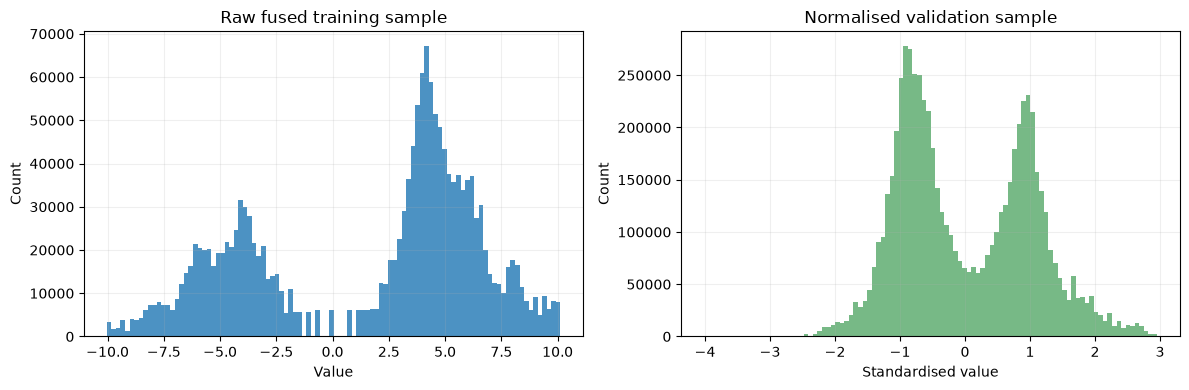

Validation mean/std: 0.014044507406651974 1.0152897834777832


In [5]:
with np.load(window_paths[VALIDATION_WINDOWS[0]], allow_pickle=False) as data:
    validation_sample = transform_fused_magnitude_iq(
        data['radar_cir_iq'][:1024], V6_CONFIG
    )
validation_normalized = normalize_per_radar_channel(
    validation_sample, V6_MEAN, V6_STD, V6_CONFIG.epsilon
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fused_sample.ravel(), bins=100, alpha=0.8)
axes[0].set(title='Raw fused training sample', xlabel='Value', ylabel='Count')
axes[1].hist(validation_normalized.ravel(), bins=100, alpha=0.8, color='#55a868')
axes[1].set(title='Normalised validation sample', xlabel='Standardised value', ylabel='Count')
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Validation mean/std:', float(validation_normalized.mean()), float(validation_normalized.std()))

## 6. Save the V6 preprocessing contract

In [6]:
artifact = {
    'representation': 'fused_magnitude_signed_iq',
    'config': {
        'radar_indices': list(V6_CONFIG.radar_indices),
        'antenna_mode': V6_CONFIG.antenna_mode,
        'range_bin_start': V6_CONFIG.range_bin_start,
        'range_bin_stop': V6_CONFIG.range_bin_stop,
        'log_compression': V6_CONFIG.log_compression,
        'background_mode': V6_CONFIG.background_mode,
        'ema_alpha': V6_CONFIG.ema_alpha,
        'epsilon': V6_CONFIG.epsilon,
    },
    'channel_order': V6_CHANNEL_ORDER,
    'input_shape': [6, 9, 120],
    'mean': V6_MEAN.tolist(),
    'std': V6_STD.tolist(),
    'training_windows': TRAIN_WINDOWS,
    'validation_windows': VALIDATION_WINDOWS,
}
output_path = ARTIFACT_DIR / 'v6_fused_normalization.json'
with output_path.open('w', encoding='utf-8') as handle:
    json.dump(artifact, handle, indent=2)
print('Saved:', output_path.resolve())

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v6_fused_normalization.json


## 7. Conclusions and technical implications

Preprocessing C combines the robust magnitude representation used by V2 with the signed quadrature representation tested by V5. Statistics are estimated exclusively from the fixed training windows, coordinates remain governed by the shared clipping/target policy, and validation windows remain untouched.

The INT8 input contains 6,480 values, approximately 6.3 KiB. The first convolution output shape remains `(6, 60, 24)`, so the largest early activation does not grow relative to V2/V5. Only the first convolution kernel grows with the additional channels. No temporal buffer, recurrent state, custom operator, Flex operator, LSTM, GRU, or RNN is introduced. V6 is accepted only if its official global F1 exceeds the V2/V5 result by a meaningful margin; otherwise the simpler candidate proceeds to full INT8 validation.